In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, classification_report, accuracy_score,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay)

df = pd.read_csv("health_data.csv")
print("Rows, columns:", df.shape)

Rows, columns: (10000, 23)


Choosing columns


Linear regression target: Claim_Amount (severity). Logistic regression target: Is_Fraud.
Approved_Amount, Premiums, Claim_Status are NOT predictors (they leak the claim amount).

In [ ]:
numeric_cols = ["Patient_Age", "No_of_Claims_Provider", "Service_Claim_days",
                "Length_of_Stay", "Prior_Visits_12m", "Chronic_Condition_Flag"]
categorical_cols = ["Insurance_Type", "Patient_Gender", "Provider_Specialty",
                    "Visit_Type", "State", "Diagnosis_Code", "Procedure_Code"]
sev_target, fraud_target = "Claim_Amount", "Is_Fraud"
lin_features = numeric_cols + categorical_cols
log_features = ["Claim_Amount"] + numeric_cols + categorical_cols

df["Provider_Specialty"] = df["Provider_Specialty"].fillna("Unknown")
for c in categorical_cols:
    df[c] = df[c].astype(str)
df[log_features + [fraud_target]].to_csv("reg_prepared_data.csv", index=False)

Train/test split

In [3]:
idx_train, idx_test = train_test_split(df.index, test_size=0.2, random_state=42,
                                       stratify=df[fraud_target])
print("Rows shared by train and test:", len(set(idx_train) & set(idx_test)))  # must be 0
train, test = df.loc[idx_train].copy(), df.loc[idx_test].copy()
print("Train:", train.shape, "Test:", test.shape)
print("Fraud rate train: %.4f test: %.4f" % (train[fraud_target].mean(), test[fraud_target].mean()))
train.to_csv("reg_train.csv", index=False)
test.to_csv("reg_test.csv", index=False)

Rows shared by train and test: 0
Train: (8000, 23) Test: (2000, 23)
Fraud rate train: 0.0829 test: 0.0830


One-hot encoding helpers

In [4]:
def encode(frame, feats):
    cats = [c for c in feats if c in categorical_cols]
    return pd.get_dummies(frame[feats], columns=cats, dtype=int)

def encode_pair(feats):
    tr = encode(train, feats)
    te = encode(test, feats).reindex(columns=tr.columns, fill_value=0)
    return tr, te

Linear regression, fit and metrics

In [5]:
Xtr_lin, Xte_lin = encode_pair(lin_features)
ref_levels = {c: sorted(train[c].unique())[0] for c in categorical_cols}
drop_cols = [f"{c}_{lvl}" for c, lvl in ref_levels.items()]
Xtr_lin, Xte_lin = Xtr_lin.drop(columns=drop_cols), Xte_lin.drop(columns=drop_cols)
ytr_lin, yte_lin = train[sev_target], test[sev_target]
print("Linear regression features:", Xtr_lin.shape[1])

lin = LinearRegression().fit(Xtr_lin, ytr_lin)
pred_lin = lin.predict(Xte_lin)
rmse = np.sqrt(mean_squared_error(yte_lin, pred_lin))
mae = mean_absolute_error(yte_lin, pred_lin)
r2 = r2_score(yte_lin, pred_lin)
base = np.full(len(yte_lin), ytr_lin.mean())
print(f"Test RMSE {rmse:.2f} | MAE {mae:.2f} | R2 {r2:.4f}")
print(f"Baseline (train mean {ytr_lin.mean():.2f}): RMSE {np.sqrt(mean_squared_error(yte_lin, base)):.2f} | MAE {mean_absolute_error(yte_lin, base):.2f}")
print("Train R2:", round(r2_score(ytr_lin, lin.predict(Xtr_lin)), 4))

Linear regression features: 43
Test RMSE 425.95 | MAE 288.89 | R2 0.0241
Baseline (train mean 572.65): RMSE 431.18 | MAE 292.47
Train R2: 0.0203


/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sharonbayela/Documents/Machine Learning for Data Science

Linear regression, coefficients and fraud check

In [6]:
coefs = pd.Series(lin.coef_, index=Xtr_lin.columns)
print("Largest coefficients ($):")
print(coefs.sort_values(key=abs, ascending=False).head(8).round(2))
print("\nNumeric coefficients:")
print(coefs[numeric_cols].round(3))

# Sensitivity check: add the fraud label as a predictor
Xtr_f, Xte_f = Xtr_lin.copy(), Xte_lin.copy()
Xtr_f["Is_Fraud"], Xte_f["Is_Fraud"] = train[fraud_target].values, test[fraud_target].values
lin_f = LinearRegression().fit(Xtr_f, ytr_lin)
print(f"\nWith Is_Fraud: R2 {r2_score(yte_lin, lin_f.predict(Xte_f)):.4f} | Is_Fraud coef {lin_f.coef_[-1]:.2f}")
print("Mean Claim_Amount legit: %.2f fraud: %.2f" %
      (df.loc[df.Is_Fraud == 0, sev_target].mean(), df.loc[df.Is_Fraud == 1, sev_target].mean()))

Largest coefficients ($):
Procedure_Code_99214    44.05
State_TX                40.78
Insurance_Type_Other   -39.89
Procedure_Code_71046    32.44
Patient_Gender_Male    -25.47
Procedure_Code_99213    23.92
Diagnosis_Code_F41.9   -22.48
Procedure_Code_97110    20.80
dtype: float64

Numeric coefficients:
Patient_Age                0.214
No_of_Claims_Provider      0.520
Service_Claim_days        -5.527
Length_of_Stay             4.372
Prior_Visits_12m           1.076
Chronic_Condition_Flag   -10.602
dtype: float64

With Is_Fraud: R2 0.1158 | Is_Fraud coef 430.39
Mean Claim_Amount legit: 535.01 fraud: 990.93


/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


Predicted vs actual plot

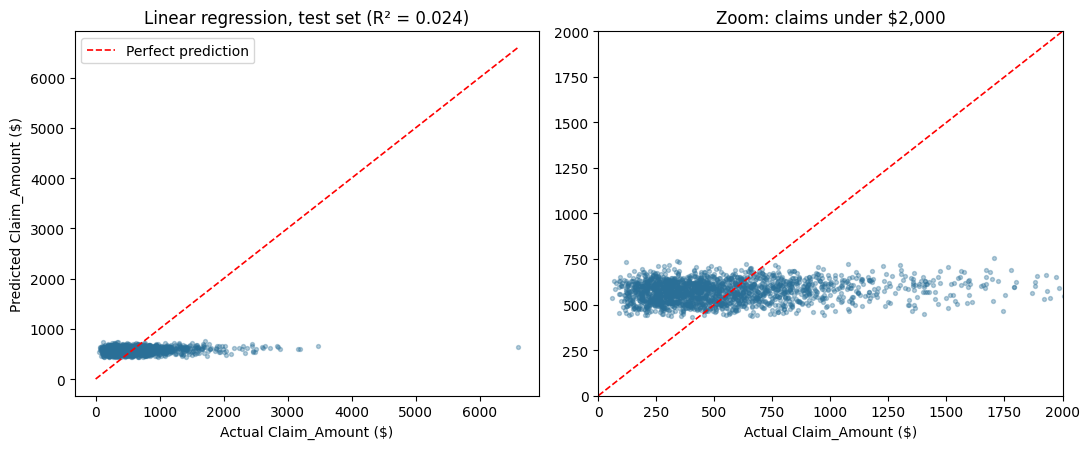

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].scatter(yte_lin, pred_lin, s=8, alpha=0.35, color="#2a6f97")
lim = [0, max(yte_lin.max(), pred_lin.max())]
ax[0].plot(lim, lim, "r--", lw=1.2, label="Perfect prediction")
ax[0].set_xlabel("Actual Claim_Amount ($)"); ax[0].set_ylabel("Predicted Claim_Amount ($)")
ax[0].set_title(f"Linear regression, test set (R² = {r2:.3f})"); ax[0].legend()
ax[1].scatter(yte_lin, pred_lin, s=8, alpha=0.35, color="#2a6f97")
ax[1].plot([0, 2000], [0, 2000], "r--", lw=1.2)
ax[1].set_xlim(0, 2000); ax[1].set_ylim(0, 2000)
ax[1].set_xlabel("Actual Claim_Amount ($)"); ax[1].set_title("Zoom: claims under $2,000")
plt.tight_layout(); plt.savefig("reg_pred_vs_actual.png", dpi=200); plt.show()

Logistic regression, scale, fit, and metrics

In [8]:
Xtr_log, Xte_log = encode_pair(log_features)
num_scale = ["Claim_Amount"] + numeric_cols
scaler = StandardScaler().fit(Xtr_log[num_scale])        
Xtr_log[num_scale] = scaler.transform(Xtr_log[num_scale])
Xte_log[num_scale] = scaler.transform(Xte_log[num_scale])
ytr_log, yte_log = train[fraud_target], test[fraud_target]
print("Logistic regression features:", Xtr_log.shape[1])

logit = LogisticRegression(class_weight="balanced", max_iter=5000, random_state=42)
logit.fit(Xtr_log, ytr_log)
pred_log = logit.predict(Xte_log)
prob_log = logit.predict_proba(Xte_log)[:, 1]
cm = confusion_matrix(yte_log, pred_log)
tn, fp, fn, tp = cm.ravel()
print(cm)
print(classification_report(yte_log, pred_log, digits=3))
print(f"Accuracy {accuracy_score(yte_log, pred_log):.4f} | ROC AUC {roc_auc_score(yte_log, prob_log):.3f} | PR AUC {average_precision_score(yte_log, prob_log):.3f}")
print(f"Specificity {tn/(tn+fp):.4f} | FP {fp} | FN {fn} | Precision {tp/(tp+fp):.4f} | Recall {tp/(tp+fn):.4f}")
print("Baseline (all legitimate) accuracy: %.4f" % (1 - yte_log.mean()))

Logistic regression features: 51
[[1571  263]
 [   9  157]]
              precision    recall  f1-score   support

           0      0.994     0.857     0.920      1834
           1      0.374     0.946     0.536       166

    accuracy                          0.864      2000
   macro avg      0.684     0.901     0.728      2000
weighted avg      0.943     0.864     0.888      2000

Accuracy 0.8640 | ROC AUC 0.960 | PR AUC 0.707
Specificity 0.8566 | FP 263 | FN 9 | Precision 0.3738 | Recall 0.9458
Baseline (all legitimate) accuracy: 0.9170


/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_st

Logistic regression, coefficients and odds

In [9]:
lcoef = pd.Series(logit.coef_[0], index=Xtr_log.columns)
odds = pd.DataFrame({"coefficient": lcoef, "odds_ratio": np.exp(lcoef)}).sort_values("coefficient", key=abs, ascending=False)
print("Largest logistic coefficients (numeric ones per 1 SD):")
print(odds.head(8).round(3))
sd = train[["Claim_Amount"] + numeric_cols].std()
print("\nOdds ratio per 1 day of Service_Claim_days: %.3f" % np.exp(lcoef["Service_Claim_days"] / sd["Service_Claim_days"]))
print("Odds ratio per $100 of Claim_Amount: %.3f" % np.exp(lcoef["Claim_Amount"] / sd["Claim_Amount"] * 100))

Largest logistic coefficients (numeric ones per 1 SD):
                                coefficient  odds_ratio
Service_Claim_days                   -5.691       0.003
Claim_Amount                          0.962       2.617
Diagnosis_Code_F41.9                 -0.584       0.558
Diagnosis_Code_N39.0                  0.580       1.786
Provider_Specialty_Pulmonology       -0.457       0.633
No_of_Claims_Provider                 0.401       1.494
Provider_Specialty_Unknown            0.399       1.490
State_NY                             -0.317       0.728

Odds ratio per 1 day of Service_Claim_days: 0.511
Odds ratio per $100 of Claim_Amount: 1.272


Confusion matrix figure

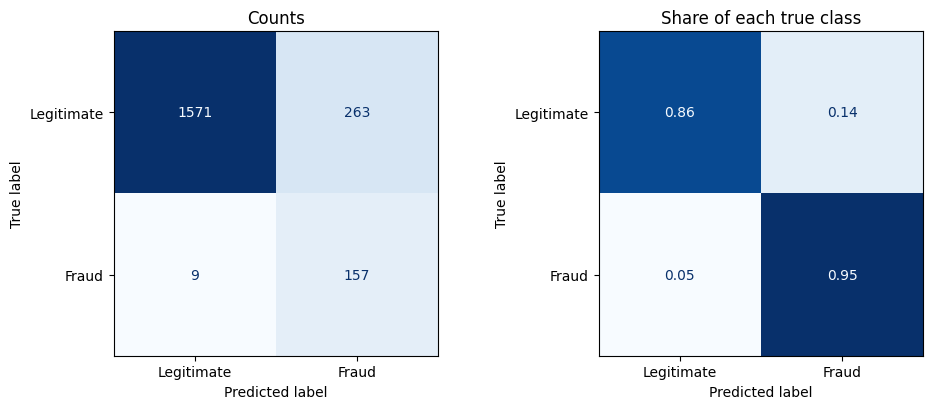

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Fraud"]).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title("Counts")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=["Legitimate", "Fraud"]).plot(
    ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[1].set_title("Share of each true class")
plt.tight_layout(); plt.savefig("reg_confusion_matrix.png", dpi=200); plt.show()

linear regression line and residuals

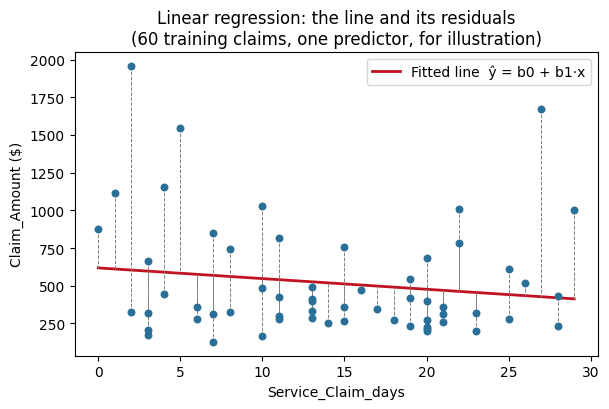

In [11]:
s = train.sample(60, random_state=42)
x, y = s["Service_Claim_days"].values, s["Claim_Amount"].values
b1, b0 = np.polyfit(x, y, 1)
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.scatter(x, y, color="#2a6f97", s=22, zorder=3)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, b0 + b1 * xs, color="#c1121f", lw=2, label="Fitted line  ŷ = b0 + b1·x")
for xi, yi in zip(x, y):
    ax.plot([xi, xi], [yi, b0 + b1 * xi], color="gray", lw=0.7, ls="--", zorder=2)
ax.set_xlabel("Service_Claim_days"); ax.set_ylabel("Claim_Amount ($)")
ax.set_title("Linear regression: the line and its residuals\n(60 training claims, one predictor, for illustration)")
ax.legend(); plt.tight_layout(); plt.savefig("reg_linear_example.png", dpi=200); plt.show()

Sigmoid

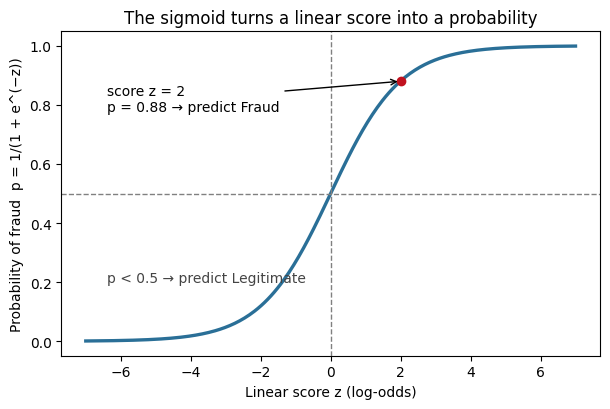

In [15]:
z = np.linspace(-7, 7, 300)
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.plot(z, 1 / (1 + np.exp(-z)), color="#2a6f97", lw=2.4)
ax.axhline(0.5, color="gray", ls="--", lw=1); ax.axvline(0, color="gray", ls="--", lw=1)
ax.scatter([2], [1 / (1 + np.exp(-2))], color="#c1121f", zorder=3)
ax.annotate("score z = 2\np = 0.88 → predict Fraud", (2, 0.88), (-6.4, 0.78), arrowprops=dict(arrowstyle="->"))
ax.text(-6.4, 0.2, "p < 0.5 → predict Legitimate", color="#444")
ax.set_xlabel("Linear score z (log-odds)"); ax.set_ylabel("Probability of fraud  p = 1/(1 + e^(−z))")
ax.set_title("The sigmoid turns a linear score into a probability")
plt.tight_layout(); plt.savefig("reg_sigmoid.png", dpi=200); plt.show()

Data sample, training, and testing table images

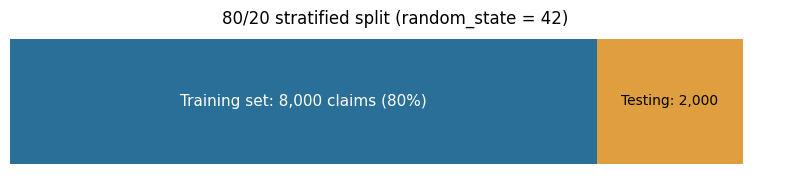

In [13]:
fig, ax = plt.subplots(figsize=(8, 1.9))
ax.barh([0], [8000], color="#2a6f97"); ax.barh([0], [2000], left=[8000], color="#e09f3e")
ax.text(4000, 0, "Training set: 8,000 claims (80%)", ha="center", va="center", color="white", fontsize=11)
ax.text(9000, 0, "Testing: 2,000", ha="center", va="center", fontsize=10)
ax.axis("off"); ax.set_title("80/20 stratified split (random_state = 42)")
plt.tight_layout(); plt.savefig("reg_train_test_split.png", dpi=200); plt.show()

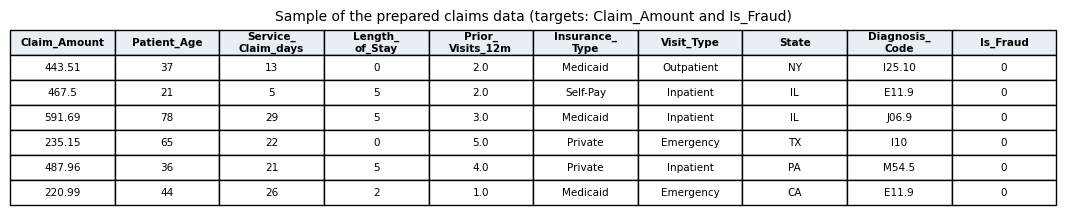

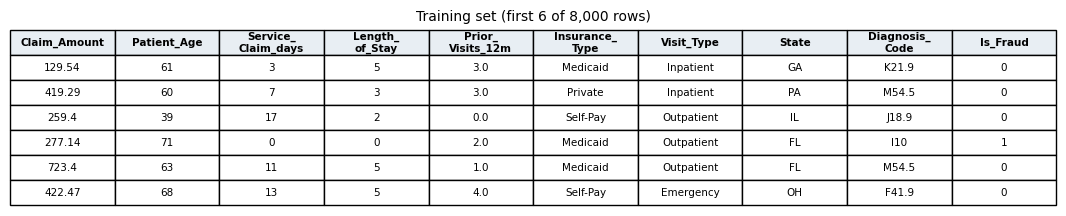

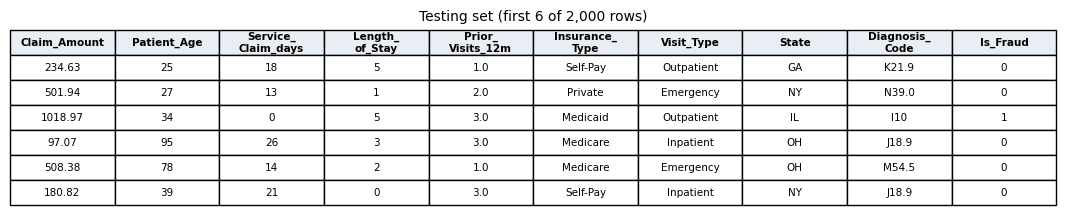

In [14]:
def table_png(frame, path, title):
    f = frame.head(6)
    fig, ax = plt.subplots(figsize=(min(1.35 * len(f.columns), 20), 2.3)); ax.axis("off")
    t = ax.table(cellText=f.round(2).values,
                 colLabels=[c.replace("_", "_\n", 1) if len(c) > 12 else c for c in f.columns],
                 loc="center", cellLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(7.5); t.scale(1, 1.5)
    for (r, c), cell in t.get_celld().items():
        if r == 0: cell.set_facecolor("#e8eef3"); cell.set_text_props(weight="bold")
    ax.set_title(title, fontsize=10); plt.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

show_cols = ["Claim_Amount", "Patient_Age", "Service_Claim_days", "Length_of_Stay", "Prior_Visits_12m",
             "Insurance_Type", "Visit_Type", "State", "Diagnosis_Code", "Is_Fraud"]
table_png(df[show_cols], "reg_data_sample.png", "Sample of the prepared claims data (targets: Claim_Amount and Is_Fraud)")
table_png(train[show_cols], "reg_train_sample.png", "Training set (first 6 of 8,000 rows)")
table_png(test[show_cols], "reg_test_sample.png", "Testing set (first 6 of 2,000 rows)")